In [41]:
import pandas as pd

In [42]:
RANDOM_STATE = 42

In [43]:
df = pd.read_parquet("../data/processed/sparcs_2024_final.parquet")

In [44]:
ADMISSION = [
    "age_group", "gender", "race", "ethnicity", "zip_code",
    "type_of_admission", "emergency_department_indicator",
    "payment_typology_1", "payment_typology_2", "payment_typology_3",
    "permanent_facility_id",
]
WITH_STAY_INFO = ADMISSION + ["ccsr_diagnosis_code","ccsr_procedure_code", "apr_medical_surgical"]
TARGET = "los"

# X, y = df[WITH_STAY_INFO], df[TARGET].astype("int64")
X, y = df[WITH_STAY_INFO], df[TARGET].astype("int64")

In [45]:
df.head()

,permanent_facility_id,age_group,zip_code,gender,race,ethnicity,type_of_admission,ccsr_diagnosis_code,apr_medical_surgical,payment_typology_1,emergency_department_indicator,ccsr_procedure_code,payment_typology_2,payment_typology_3,los
0,001139,0-17,OOS,F,White,Not Span/Hispanic,Emergency,SYM002,Medical,Private Health Insurance,Y,No procedure recorded,No second payer,No third payer,1
1,001628,0-17,113,M,White,Spanish/Hispanic,Emergency,SYM002,Medical,Medicaid,Y,No procedure recorded,No second payer,No third payer,2
2,001458,70 or Older,100,M,White,Not Span/Hispanic,Emergency,SYM002,Medical,Medicare,Y,ADM012,Private Health Insurance,No third payer,2
3,001464,0-17,100,F,Other Race,Not Span/Hispanic,Emergency,SYM002,Medical,Private Health Insurance,Y,CNS002,No second payer,No third payer,1
4,001466,18-29,100,F,Other Race,Spanish/Hispanic,Emergency,SYM002,Medical,Medicare,Y,ADM021,No second payer,No third payer,1


In [46]:
CATEGORICAL = ["permanent_facility_id","zip_code","gender","race","ethnicity","type_of_admission","ccsr_diagnosis_code","apr_medical_surgical","payment_typology_1","payment_typology_2","payment_typology_3","emergency_department_indicator","ccsr_procedure_code"]
ORDINAL = ["age_group"]
CONTINUOUS = []
ORDIANL_CATS = [["0-17","18-29","30-49","50-69","70 or Older"]]

### Interaction Term Candidate Pairs

In [47]:

candidates = [("ccsr_diagnosis_code", "age_group"),("ccsr_diagnosis_code", "type_of_admission"),("type_of_admission", "age_group"),("type_of_admission", "race"),("zip_code","type_of_admission")]

Interaction plots use the training portion only, so the test set is never looked at.
Parallel lines mean the two features add up (no interaction needed). Lines that diverge or cross suggest an interaction.

In [48]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

X_train_val,X_test,y_train_val, y_test = train_test_split(X,y, test_size=0.2, random_state=RANDOM_STATE)

In [49]:
def interaction_plot(data,y, line_ftr, x_ftr, top_n=10):
    lines = data[line_ftr].value_counts().index[:top_n] #all features are categorical so keep top 10 categories
    x_order = ORDIANL_CATS[0] if x_ftr == "age_group" else data[x_ftr].value_counts().index[:top_n]
    subset = data[data[line_ftr].isin(lines) & data[x_ftr].isin(x_order)]

    mean_los = pd.crosstab(subset[line_ftr], subset[x_ftr],values=y.loc[subset.index], aggfunc="mean")[list(x_order)]

    plt.figure(figsize=(8, 5))
    for level, row in mean_los.iterrows():
        plt.plot(range(len(x_order)), row.values, marker="o", label=level)
    plt.xticks(range(len(x_order)), x_order, rotation=30)
    plt.xlabel(x_ftr)
    plt.ylabel("mean length of stay (days)")
    plt.title(f"{line_ftr} x {x_ftr}")
    plt.legend(title=line_ftr, loc="upper left", fontsize=8)
    plt.tight_layout()
    plt.savefig(f"../figures/interaction_{line_ftr}_x_{x_ftr}.png", dpi=300)
    plt.show()

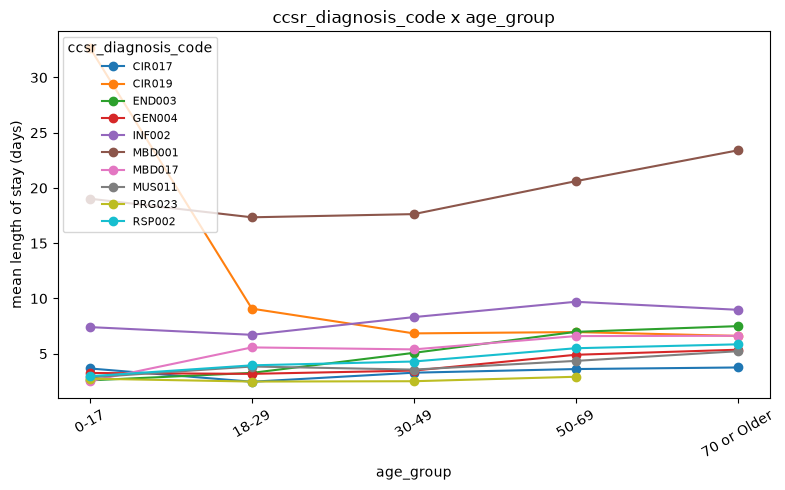

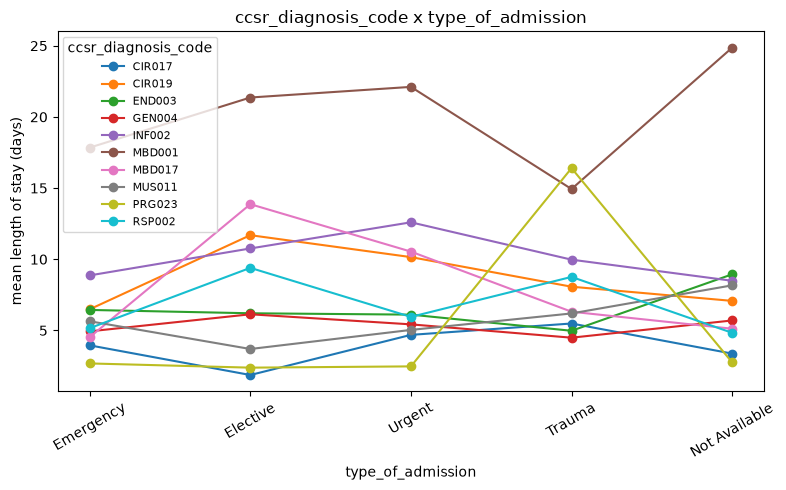

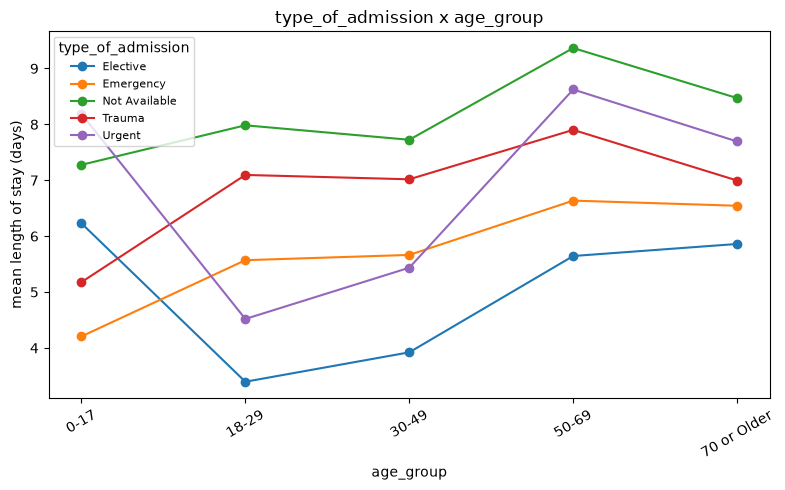

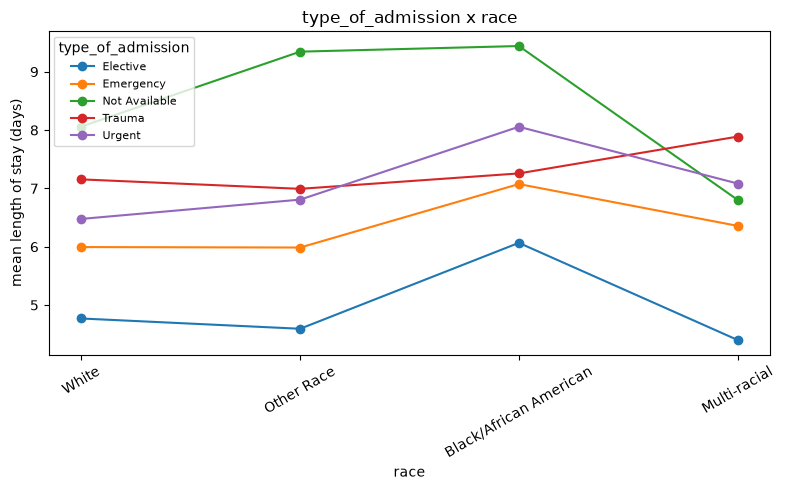

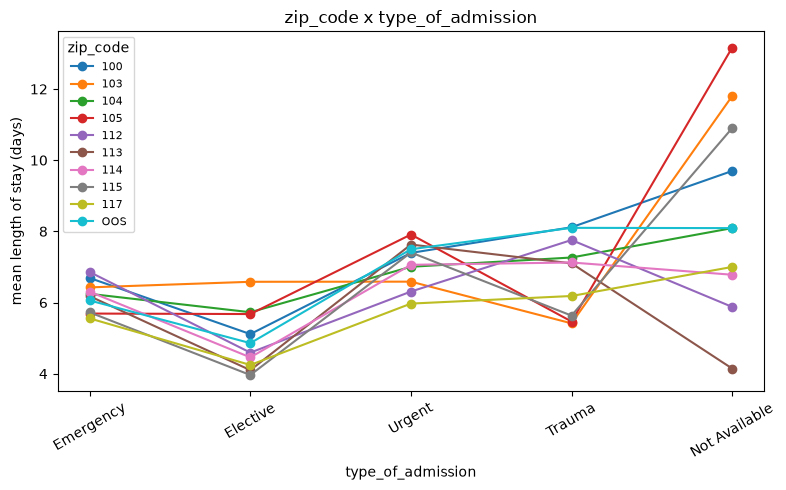

In [50]:
for line_ftr, x_ftr in candidates:
    interaction_plot(X_train_val,y_train_val, line_ftr, x_ftr)

In [27]:
pd.crosstab(X_train_val["ccsr_diagnosis_code"],X_train_val["type_of_admission"])

type_of_admission,Elective,Emergency,Not Available,Trauma,Urgent
ccsr_diagnosis_code,,,,,
BLD001,29,4261,1,0,107
BLD002,37,474,1,0,48
BLD003,99,2301,7,5,125
BLD004,51,3495,5,9,136
BLD005,104,6430,12,3,172
...,...,...,...,...,...
SYM015,16,1788,2,2,32
SYM016,846,3448,10,27,207
SYM017,576,1888,7,4,174


In [29]:
pd.crosstab(X_train_val["ccsr_diagnosis_code"],X_train_val["age_group"])

age_group,0-17,18-29,30-49,50-69,70 or Older
ccsr_diagnosis_code,,,,,
BLD001,195,158,902,1101,2042
BLD002,109,57,68,140,186
BLD003,143,92,346,716,1240
BLD004,29,103,622,937,2005
BLD005,1236,2307,2571,570,37
...,...,...,...,...,...
SYM015,19,24,139,681,977
SYM016,737,60,204,881,2656
SYM017,192,102,440,914,1001


In [30]:
pd.crosstab(X_train_val["age_group"],X_train_val["type_of_admission"])

type_of_admission,Elective,Emergency,Not Available,Trauma,Urgent
age_group,,,,,
0-17,11960,62185,116,266,8166
18-29,39572,83114,238,819,21809
30-49,86573,210079,609,1579,38044
50-69,76820,351102,902,1885,33704
70 or Older,69539,458287,1047,3454,32917


In [35]:
pd.crosstab(X_train_val["zip_code"],X_train_val["type_of_admission"])

type_of_admission,Elective,Emergency,Not Available,Trauma,Urgent
zip_code,,,,,
100,18783,83054,56,460,9012
101,779,2259,2,4,371
103,4267,30789,5,723,6364
104,20378,124946,44,1090,7348
105,8741,31477,168,15,1994
106,1241,5431,13,0,241
107,2731,17270,98,11,661
108,1092,5003,12,2,186
109,9776,28529,172,385,1814


In [40]:
pd.crosstab(X_train_val["race"],X_train_val["type_of_admission"])

type_of_admission,Elective,Emergency,Not Available,Trauma,Urgent
race,,,,,
Black/African American,37084,238707,347,1546,19214
Multi-racial,4476,16129,51,232,1574
Other Race,77954,310952,682,1633,38453
White,164950,598979,1832,4592,75399


- ccsr_diagnosis_code x age_group are mostly parallel lines but the CIR019 and 0-17 age group has a large spikes where the diagnosis is not exactly parallel. The count is 42 for CIR019,0-17 which is the least number of samples compared to the other age groups for the diagnosis, but it is large enough for it to be significant.
- Due to the spike it will be used as a interaction term
- ccsr_diagnosis_code x type_of_emergency will be used since there is crossover of the lines indicating interaction.
- The spike for PRG023xTrauma in ccsr_diagnosis_code x type_of_emergency could be due to the small number of samples but otherwise the crossover makes it a good candidate
- type_of_admission x age_group is also a candidate but it is weaker since the lines are mostly parallel but with a few crossover for some levels of age_group
- zip_code x type_of_admission is not used as a interaction term due to the crossover happening where there are very few samples.
- type_of_admission x race is used as a interaction term since it has some crossover for the Trauma admission for multi-racial patients